# Overview

The equations of motion are
$$\begin{aligned}
\dot x &= \cos \varphi \\
\dot y &= \sin \varphi \\
\dot \varphi &= \sqrt\sigma \xi_\varphi
\end{aligned}$$

With noise level $\sigma = T/t^*$, where $T$ is the time between two observations and $t^*$ is the persistence time of the particle.

# Initialization and Functions

## Imports, Sorter, Brigde Generator

In [1]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal as mvn
from scipy.stats import binned_statistic_2d
from scipy.stats import skewnorm, skew
from scipy.ndimage import zoom, gaussian_filter
from tqdm import tqdm
from inference_tools import ParticleFilter, crng, HilbertSorter, ConditionedBridge
from matplotlib import patches as mpatches
import matplotlib as mpl
from matplotlib import cm as cm
from scipy.stats import multivariate_normal, binom
from scipy.optimize import fsolve
from scipy.optimize import minimize, differential_evolution
from itertools import product
#plt.style.use('dark_background')

sorter = HilbertSorter(depth=9, dims=2)
bridge_gen = ConditionedBridge()

def collect_quantile(quantile, value, mass):
    value = value.flatten()
    mass = mass.flatten()
    srt_idx = np.argsort(value)
    value = value[srt_idx]
    mass = mass[srt_idx]
    mass_tot = np.sum(mass)
    prop = mass / mass_tot
    cumprop = np.cumsum(prop)
    midx = np.argmax(cumprop > quantile)
    return value[midx]

## Helper functions

In [2]:
global tic_time
tic_time = None

def tic():
    global tic_time
    tic_time = time.time()

def toc():
    global tic_time
    if tic_time is not None:
        elapsed_time = time.time() - tic_time
        hours, remainder = divmod(elapsed_time, 3600)
        minutes, seconds = divmod(remainder, 60)
        if hours > 0:
            print(f"Elapsed time: {int(hours)} hours, {int(minutes)} minutes, {int(seconds)} seconds")
        elif minutes > 0:
            print(f"Elapsed time: {int(minutes)} minutes, {int(seconds)} seconds")
        else:
            print(f"Elapsed time: {elapsed_time:.2f} seconds")
    else:
        print("Call tic() before calling toc()")

tic()

## Simulation Constants

We collect a few constants that control aspects of the simulations, to maintain some consistency between the different scenarios.

In [3]:
_THE_DT_                  = 5e-3
_THE_SIGMAS_              = np.logspace(3, -2, 20)
_THE_SHIFTS_              = np.linspace(0, 1, 9)
_THE_SLOPES_              = np.linspace(0, 3, 9)
_THE_NUMBER_OF_PARTICLES_ = int(3e6)

mpl.rcParams['figure.dpi'] = 300

## Equation of Motion

In [4]:
def abp_sde(X0, params, T0=0, T1=1):
    
    ''' SDE for ABP '''
    
    output_hires = params.get('output_hires', False)
    omit_bridges = params.get('omit_bridges', False)
    use_bridge_mean = params.get('use_bridge_mean', False)
    target_shift_P = params.get('target_shift_PHI', 0)
    target_slope_P = params.get('target_slope_PHI', 0)
    
    BridgeGen = params['BridgeGen']
    RNG = params['RNG']
    sigma = params['sigma']
    _id = params.get('id', -1)
    
    dt  = params['dt']
    
    X = X0.copy()
    T = T0
    step = 0
    
    if output_hires:
        hires  = [X.copy()]
        hiresT = [T]
        
    n_steps = int((T1 - T0) / dt + 1)
    n_parts = X.shape[0]
    dt_ = (T1 - T0) / n_steps
    
    if not omit_bridges:
        
        assert sigma > 0, f"Bridge needs noise, but sigma is set to {sigma}"

        shiftP = target_shift_P / (dt_ * np.sqrt(dt_ * sigma)) * np.ones(n_parts)
        slopeP = target_slope_P / (np.sqrt(dt_ * sigma)) * np.ones(n_parts)

        bridge_res_P = BridgeGen.get(n_steps + 1, shiftP, slopeP, ('abpsdePbridgegen', _id, T0, T1), 0.0, RNG, use_bridge_mean)
        
        wP  = bridge_res_P['w']
        dwP = np.diff(wP, axis=0)
        dwP = np.concatenate([wP[[0],:], dwP])
        ddP = np.diff(dwP, axis=0).T

        w = ddP
        
        logl = np.mean(-(slopeP/bridge_res_P['std1'])**2 - (shiftP/bridge_res_P['std2'])**2)
        
    else:
        
        w = RNG.get(('abpsde_full', _id, T0, T1), (n_parts, n_steps), corr=0)
        logl=0

        
    for k in range(n_steps):

        ''' Integrate the EOM '''

        dx = np.cos(X[:, 2])
        dy = np.sin(X[:, 2])
        drift = np.stack([dx, dy, np.zeros_like(dx)], axis=1)

        #X += np.sqrt(dt_) * w[..., k] * np.sqrt(D)
        X[:,2] += np.sqrt(dt_ * sigma) * w[:, k]
        X += dt_ * drift
        
        if output_hires:
            hires.append(X.copy())
            hiresT.append(T)
    
    res_dict = dict(X1=X, logl=logl)
    
    if output_hires:
        res_dict['per_particle_streams'] = dict(hires=np.stack(hires, -1))

    return res_dict

In [5]:
def run(N, sigma, shift, slope, params, batch_size=1000, use_tqdm=False):
    
    ''' Helper function that takes parameters that we're interested in this Notebook,
        exectutes a run and returns the endpoints of the simulations '''
    
    params['output_hires'] = False
    params.update(dict(sigma = sigma,
                       target_shift_PHI = shift,
                       target_slope_PHI = slope,
                       output_hires = False,
                      )
                 )
    
    if N < batch_size:
        batch_size = N
    n_batches = int(N / batch_size)
    
    if use_tqdm:
        range_ = tqdm(range(n_batches))
    else:
        range_ = range(n_batches)
    
    x = []
    y = []
    
    for b_ in range_:
        X0 = np.zeros((batch_size, 3))
        params['RNG'].reroll(0)
        sim_res = abp_sde(X0, params)
        x.append(sim_res['X1'][:, 0])
        y.append(sim_res['X1'][:, 1])
    
    x = np.concatenate(x, axis=0)
    y = np.concatenate(y, axis=0)
    
    return dict(x=x, y=y)

## Analysis functions

In [6]:
def analyze(res, purge_raw_data = False):
    
    ''' Get basic endpoint statistics and do the rotation transformation of the data '''
    
    res.update(dict(x_loc  = np.mean(res['x']),
                    y_loc  = np.mean(res['y']),
                    x_std   = np.std(res['x']),
                    y_std   = np.std(res['y']),
                    x_skew   = skew(res['x']),
                    y_skew = skew(res['y']),
                   )
              )
    
    angle = np.arctan2(res['y_loc'], res['x_loc'])
    x_rot = np.cos(-angle) * res['x'] - np.sin(-angle) * res['y']
    y_rot = np.sin(-angle) * res['x'] + np.cos(-angle) * res['y']

    res.update(dict(x_rot = x_rot,
                    y_rot = y_rot,
                   )
              )
    
    res.update(dict(x_loc_rot  = np.mean(res['x_rot']),
                    y_loc_rot  = np.mean(res['y_rot']),
                    x_med_rot  = np.median(res['x_rot']),
                    y_med_rot  = np.median(res['y_rot']),
                    x_std_rot  = np.std(res['x_rot']),
                    y_std_rot  = np.std(res['y_rot']),
                    x_skew_rot = skew(res['x_rot']),
                    y_skew_rot = skew(res['y_rot']),
                   )
              )
    
    if purge_raw_data:
        del res['x']
        del res['y']
    

In [7]:
def density_analysis(run, use_rotated = True, edge_size=0.1, nbins=1000):
    
    ''' Construct the density map of the particles '''
    
    x_ = run['x_rot'] if use_rotated else run['x']
    y_ = run['y_rot'] if use_rotated else run['y']
    
    xmin, ymin = x_.min(), y_.min()
    xmax, ymax = x_.max(), y_.max()
    
    dx = xmax - xmin
    dy = ymax - ymin
    
    xmin -= edge_size * dx
    xmax += edge_size * dx
    ymin -= edge_size * dy
    ymax += edge_size * dy
    
    range_ = (xmin, xmax), (ymin, ymax)
    extent = xmin, xmax, ymin, ymax
    
    statistic = binned_statistic_2d(x_, y_, None, statistic='count', bins=nbins, range=range_)
    
    binx = (statistic.x_edge[1:] + statistic.x_edge[:-1]) / 2
    biny = (statistic.y_edge[1:] + statistic.y_edge[:-1]) / 2

    run.update(dict(d_extent = extent,
                    d_statistic = statistic.statistic.T,
                    d_binx = binx,
                    d_biny = biny,
                   )   
              )

In [8]:
''' DEPRECATED 1D VERSION
def maximize_data_likelihood(run, sigma, use_rotated=True, restrict_to_x=True, ref_run=None):
    
    n_pts = len(run['x'])
    X = np.stack((run['x'], run['y']), axis=-1)
    X0 = np.array((run['x_loc'], run['y_loc']))
    
    mu0 = run['x_loc']
    
    def loss(mu):
        return -np.sum(multivariate_normal.pdf(X, mean=(mu[0], 0), cov=sigma**2)) / n_pts
        
    opt_res = differential_evolution(loss, ((0, 1), ))
    
    opt_likelihood_ref = None
    if ref_run is not None:
        n_pts_r = len(ref_run['x'])
        Xr = np.stack((ref_run['x'], ref_run['y']), axis=-1)
        opt_likelihood_ref = np.sum(multivariate_normal.pdf(Xr, mean=(opt_res.x[0], 0), cov=sigma**2)) / n_pts_r
        
    
    run.update(dict(opt_mu_x = opt_res.x,
                    opt_mu_y = 0,
                    opt_sigma = sigma,
                    opt_success = opt_res.success,
                    opt_res = opt_res,
                    opt_likelihood = -opt_res.fun,
                    opt_likelihood_reference = opt_likelihood_ref,
                   )
              )
'''  

" DEPRECATED 1D VERSION\ndef maximize_data_likelihood(run, sigma, use_rotated=True, restrict_to_x=True, ref_run=None):\n    \n    n_pts = len(run['x'])\n    X = np.stack((run['x'], run['y']), axis=-1)\n    X0 = np.array((run['x_loc'], run['y_loc']))\n    \n    mu0 = run['x_loc']\n    \n    def loss(mu):\n        return -np.sum(multivariate_normal.pdf(X, mean=(mu[0], 0), cov=sigma**2)) / n_pts\n        \n    opt_res = differential_evolution(loss, ((0, 1), ))\n    \n    opt_likelihood_ref = None\n    if ref_run is not None:\n        n_pts_r = len(ref_run['x'])\n        Xr = np.stack((ref_run['x'], ref_run['y']), axis=-1)\n        opt_likelihood_ref = np.sum(multivariate_normal.pdf(Xr, mean=(opt_res.x[0], 0), cov=sigma**2)) / n_pts_r\n        \n    \n    run.update(dict(opt_mu_x = opt_res.x,\n                    opt_mu_y = 0,\n                    opt_sigma = sigma,\n                    opt_success = opt_res.success,\n                    opt_res = opt_res,\n                    opt_likeliho

In [9]:
''' UPDATED 2D VERSION '''
def maximize_data_likelihood(run, sigma, use_rotated=True, restrict_to_x=False, ref_run=None):
    
    n_pts = len(run['x'])
    X = np.stack((run['x'], run['y']), axis=-1)
    X0 = np.array((run['x_loc'], run['y_loc']))
    
    mu0 = run['x_loc']
    
    def loss(mu):
        return -np.sum(multivariate_normal.pdf(X, mean=(mu[0], 0 if restrict_to_x else mu[1]), cov=sigma**2)) / n_pts
        
    opt_res = differential_evolution(loss, ((0, 1), (-1, 1)))
    
    opt_likelihood_ref = None
    if ref_run is not None:
        n_pts_r = len(ref_run['x'])
        Xr = np.stack((ref_run['x'], ref_run['y']), axis=-1)
        opt_likelihood_ref = np.sum(multivariate_normal.pdf(Xr, mean=(opt_res.x[0], 0 if restrict_to_x else opt_res.x[1]), cov=sigma**2)) / n_pts_r
        
    
    run.update(dict(opt_mu_x = opt_res.x[0],
                    opt_mu_y = 0 if restrict_to_x else opt_res.x[1] ,
                    opt_sigma = sigma,
                    opt_success = opt_res.success,
                    opt_res = opt_res,
                    opt_likelihood = -opt_res.fun,
                    opt_likelihood_reference = opt_likelihood_ref,
                   )
              )

In [10]:
def analyze_series_max_likelihood(results, sigma, use_tqdm=False, reference_results=None):
        
    sig = []
    lkhd = []
    lkhd_ref = []
    
    if reference_results is None:
        reference_results = [None] * len(results)
    
    Rzip_ = list(zip(results, reference_results))
    R_ = tqdm(Rzip_) if use_tqdm else Rzip_
    
    for res_, res_ref_ in R_:
        density_analysis(res_)
        maximize_data_likelihood(res_, sigma=sigma, ref_run=res_ref_)
        sig.append(res_['sigma'])
        lkhd.append(res_['opt_likelihood'])
        lkhd_ref.append(res_['opt_likelihood_reference'])
            
    return dict(sigma=np.array(sig), likelihood=np.array(lkhd), likelihood_reference=np.array(lkhd_ref))

## Plot functions

In [11]:
def plot_mean_distance(results, show_y=True,
                       show_rot=True, show_unrot=True, 
                       x_color='royalblue', y_color='deeppink',
                       x_label='x', y_label='y',
                       rot_style='-',
                      ):
    sig = [res['sigma'] for res in results]
    xlocs = [res['x_loc'] for res in results]
    ylocs = [res['y_loc'] for res in results]
    xlocs_rot = [res['x_loc_rot'] for res in results]
    ylocs_rot = [res['y_loc_rot'] for res in results]
    if show_unrot:
        plt.semilogx(sig, xlocs, '--', color=x_color, linewidth=0.8, alpha=0.5)
        if show_y:
            plt.semilogx(sig, ylocs, '--', color=y_color, linewidth=0.8, alpha=0.5)
    
    if show_rot:
        plt.semilogx(sig, xlocs_rot, rot_style, color=x_color, linewidth=2, label=x_label)
        if show_y:
            plt.semilogx(sig, ylocs_rot, rot_style, color=y_color, linewidth=2, label=y_label)
    plt.suptitle("Mean distance")
    plt.xlabel("Noise")
    plt.ylabel("x, y")

In [12]:
def plot_std(results, show_rot=True, show_unrot=False,
             x_color='royalblue', y_color='deeppink',
             x_label='x', y_label='y',
             rot_style='-',
            ):
    sig = [res['sigma'] for res in results]
    xstd = [res['x_std'] for res in results]
    ystd = [res['y_std'] for res in results]
    xstd_rot = [res['x_std_rot'] for res in results]
    ystd_rot = [res['y_std_rot'] for res in results]
    if show_unrot:
        plt.loglog(sig, xstd, '--', color=x_color, linewidth=0.8, alpha=0.5)
        plt.loglog(sig, ystd, '--', color=y_color, linewidth=0.8, alpha=0.5)
    
    if show_rot:
        plt.loglog(sig, xstd_rot, rot_style, color=x_color, linewidth=2, label=x_label)
        plt.loglog(sig, ystd_rot, rot_style, color=y_color, linewidth=2, label=y_label)
        
    plt.suptitle("Width / Standard Deviation")
    plt.xlabel("Noise"), plt.ylabel("STD")

In [13]:
def plot_skew(results, show_rot=True, show_unrot=False,
              x_color='royalblue', y_color='deeppink',
              x_label='x', y_label='y',
              rot_style='-',
              gaussian_filter_sigma=1
            ):
    sig = [res['sigma'] for res in results]
    xskews = gaussian_filter([res['x_skew'] for res in results], gaussian_filter_sigma)
    yskews = gaussian_filter([res['y_skew'] for res in results], gaussian_filter_sigma)
    xskews_rot = gaussian_filter([res['x_skew_rot'] for res in results], gaussian_filter_sigma)
    yskews_rot = gaussian_filter([res['y_skew_rot'] for res in results], gaussian_filter_sigma)
    if show_unrot:
        plt.semilogx(sig, xskews, '--b', linewidth=0.8, alpha=0.5)
        plt.semilogx(sig, yskews, '--r', linewidth=0.8, alpha=0.5)
    if show_rot:
        plt.semilogx(sig, xskews_rot, rot_style, color=x_color, linewidth=2, label=x_label)
        plt.semilogx(sig, yskews_rot, rot_style, color=y_color, linewidth=2, label=y_label)
    plt.suptitle("Skew")
    plt.xlabel("Noise")
    plt.ylabel("Skew")

In [14]:
def plot_density(S, c='k', gaussian_filter_sigma=1,
                 offset_y=0,
                 plot_density=True,
                 plot_optimization_result=False,
                 optimization_style='--b',
                ):
    if plot_density:
        stat_filt = gaussian_filter(S['d_statistic'], gaussian_filter_sigma)
        quantiles = [0.01, 0.10, 0.5, 0.95]
        levels = [collect_quantile(q, stat_filt, stat_filt) for q in quantiles]

        plt.contour(S['d_binx'], S['d_biny']+offset_y,
                    stat_filt,
                    levels=levels,
                    colors=c,
                    linestyles=['--', '--', '-', '-'],linewidths=[0.5, 0.5, 1.0, 2.5],
                   )
    
    if plot_optimization_result:
        phi = np.linspace(0, 2*np.pi, 128)
        cx  = np.cos(phi) * S['opt_sigma'] + S['opt_mu_x']
        cy  = np.sin(phi) * S['opt_sigma'] + S['opt_mu_y']
        plt.plot(cx, cy, optimization_style)

    plt.xlabel("x")
    plt.ylabel("y")

In [15]:
def plot_optimal_likelihood(results, sigma,
                            series_result=None,
                            use_tqdm=False,
                            style='-k',
                            color=None,
                            label=None,
                            likelihood_cutoff=1e-10,
                            reference_results=None,
                           ):
    d = series_result if series_result is not None else analyze_series_max_likelihood(results, sigma,
                                                                                      use_tqdm,
                                                                                      reference_results=reference_results)
    idx = d['likelihood'] > likelihood_cutoff
    plt.loglog(d['sigma'][idx], d['likelihood'][idx] / _THE_NUMBER_OF_PARTICLES_, style, label=label, c=color)
    return d

# Analysis of Bridges

## Basic Bridge Plot

loglikelihood: 0.0
loglikelihood: 0.0


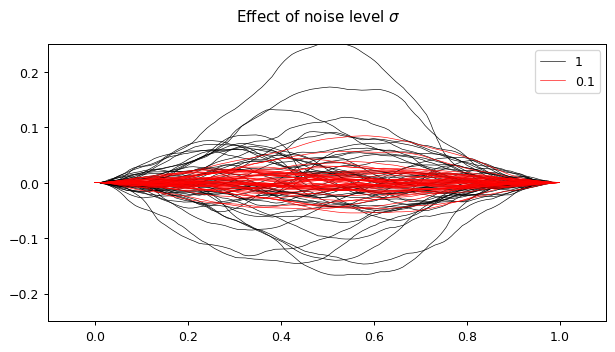

In [16]:
N = 50
dt = 1e-2
X0 = np.zeros((N, 3))
params = dict(RNG=crng(), BridgeGen=bridge_gen,
              sigma = 1,
              dt = dt,
              target_shift_PHI=0,
              target_slope_PHI=0*np.pi,
              output_hires=True,
              omit_bridges=False,
              use_tqdm = False,
             )

sim_res = abp_sde(X0, params)
x = sim_res['per_particle_streams']['hires'][:,0,:].T
y = sim_res['per_particle_streams']['hires'][:,1,:].T
print('loglikelihood:', sim_res['logl'])
plt.figure(figsize=(8,4))
plt.plot(x,y, 'k', alpha=1, linewidth=0.5)
plt.plot([],[], 'k', alpha=1, label=params['sigma'], linewidth=0.5)


params['sigma'] = 0.1
sim_res = abp_sde(X0, params)
x = sim_res['per_particle_streams']['hires'][:,0,:].T
y = sim_res['per_particle_streams']['hires'][:,1,:].T
print('loglikelihood:', sim_res['logl'])
plt.plot(x,y, 'r', alpha=1, linewidth=0.5)
plt.plot([],[], 'r', alpha=1, label=params['sigma'], linewidth=0.5)



plt.xlim([-.1,1.1])
plt.ylim([-.25,.25])
#plt.axhline(params['target_shift_PHI'], linestyle='--')
#plt.gca().axis('equal')
plt.suptitle("Effect of noise level $\sigma$")
plt.legend()
plt.show()

## Unconditioned Particles

We start with unconditioned trajectories as a baseline for comparison with the bridges.

### Data generation

Generate dataset `results_unconditioned`, containing the endpoints for particles from the unconditioned EOM.

We sweep through a range of noise levels $\sigma$.

In [17]:
params = dict(BridgeGen=bridge_gen,
              sigma = 1,
              dt = _THE_DT_,
              target_shift_PHI=0,
              target_slope_PHI=0*np.pi,
              output_hires=True,
              omit_bridges=False,
              use_tqdm = False,
             )

params['RNG'] = crng()

N = _THE_NUMBER_OF_PARTICLES_
results_unconditioned = []
params['omit_bridges'] = True
for sigma_ in tqdm(_THE_SIGMAS_):
    res = run(N=N, sigma=sigma_, shift=0, slope=0*np.pi/2, params=params, use_tqdm=False)
    analyze(res, purge_raw_data=False)
    density_analysis(res)
    res['sigma'] = sigma_
    results_unconditioned.append(res)
    
toc()

100%|███████████████████████████████████████████| 20/20 [00:12<00:00,  1.62it/s]

Elapsed time: 12.62 seconds


### Density Plot

/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_52849/2647874874.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('inferno', len(res_))
100%|█████████████████████████████████████████████| 4/4 [00:01<00:00,  2.44it/s]


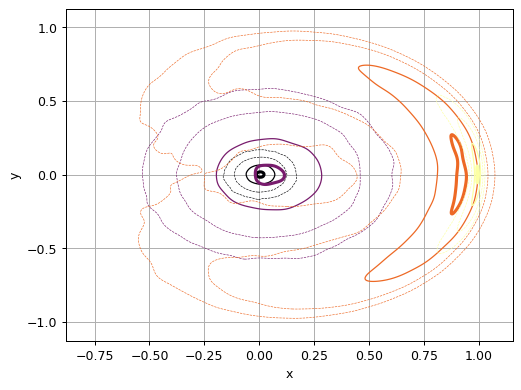

In [18]:
res_ = results_unconditioned[::5]
cmap = cm.get_cmap('inferno', len(res_))
for i, r_ in tqdm(enumerate(res_),total=len(res_)):
    plot_density(r_, c=cmap(i), gaussian_filter_sigma=20)
    
plt.grid()
plt.savefig("img/5/1_dens_uncond.png")
plt.show()

### Localization

Analyzing the transition density function of the unconditioned simulation.

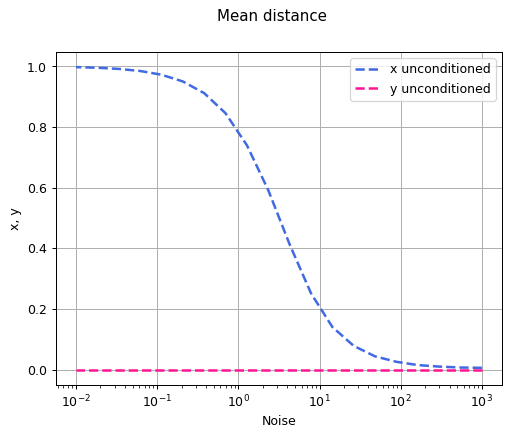

In [19]:
plot_mean_distance(results_unconditioned,
                   show_unrot=False, show_y=True,
                   x_label='x unconditioned', y_label='y unconditioned',
                   rot_style='--',
                  )
plt.grid()
plt.legend()
plt.savefig("img/5/2_mean_uncond.png")
plt.show()

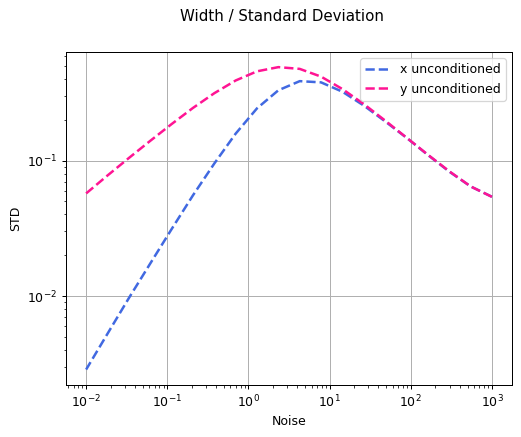

In [20]:
plot_std(results_unconditioned,
         x_label='x unconditioned',
         y_label='y unconditioned',
         rot_style='--'
        )
plt.legend(), plt.grid()
plt.savefig("img/5/3_std_uncond.png")
plt.show()

### Efficiency

100%|█████████████████████████████████████████████| 3/3 [00:06<00:00,  2.25s/it]


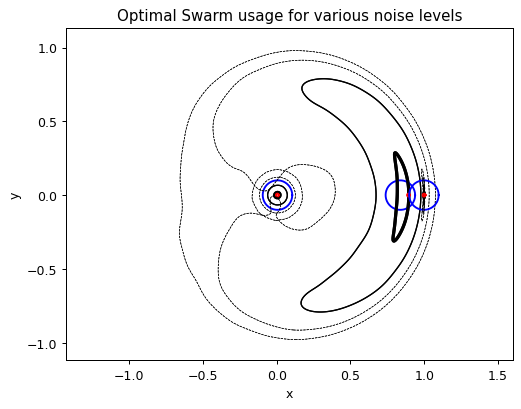

Elapsed time: 21.64 seconds


In [21]:
for res_ in tqdm([results_unconditioned[i] for i in [0, 9, -1]]):
    density_analysis(res_)
    maximize_data_likelihood(res_, sigma=1e-1, restrict_to_x=True)
    plot_density(res_, gaussian_filter_sigma=30, plot_optimization_result=True, optimization_style='-b')
    maximize_data_likelihood(res_, sigma=1e-2, restrict_to_x=True)
    plot_density(res_, gaussian_filter_sigma=30, plot_optimization_result=True, optimization_style='-r')
    #plt.xlim((-0.5,1.5))
    #plt.ylim((-1.5,1.5))
plt.title('Optimal Swarm usage for various noise levels')
plt.gca().axis('equal')
plt.savefig("img/5/4_dens_opt_uncond.png")
plt.show()
toc()

## Null Conditioning

We condition the trajectories with zero offset and zero final slope.

### Data Generation

In [22]:
params = dict(BridgeGen=bridge_gen,
              sigma = 1,
              dt = _THE_DT_,
              target_shift_PHI=0,
              target_slope_PHI=0*np.pi,
              output_hires=True,
              omit_bridges=False,
              use_tqdm = False,
             )

params['RNG'] = crng()

N = _THE_NUMBER_OF_PARTICLES_
results_null = []
for sigma_ in tqdm(_THE_SIGMAS_):
    res = run(N=N, sigma=sigma_, shift=0., slope=0, params=params, use_tqdm=False)
    analyze(res)
    res['sigma'] = sigma_
    results_null.append(res)

toc()

100%|███████████████████████████████████████████| 20/20 [00:18<00:00,  1.10it/s]

Elapsed time: 39.77 seconds


### Density Plots

/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_52849/3220471424.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('inferno', len(res_))
0it [00:00, ?it/s]
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


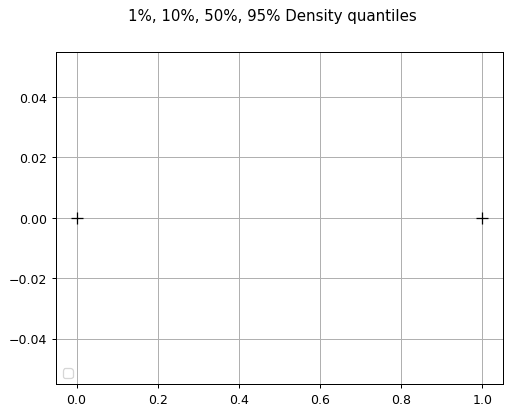

In [23]:
res_ = results_null[10:-25:3]
cmap = cm.get_cmap('inferno', len(res_))
for i, r_ in tqdm(enumerate(res_), total=len(res_)):
    density_analysis(r_, use_rotated=True, nbins=500)
    plot_density(r_, c=cmap(i), gaussian_filter_sigma=5)
    plt.plot([],[], color=cmap(i), label=f"$\sigma=${r_['sigma']:.0f}")

    
#plt.xlim((0.9875,1)), plt.ylim((-0.00005, 0.0004))
plt.plot([0],[0],'+k', markersize=10)
plt.plot([1],[0],'+k', markersize=10)
plt.grid()
plt.legend(loc='lower left')
plt.suptitle("1%, 10%, 50%, 95% Density quantiles")
plt.savefig("img/5/5_dens_null.png")
plt.show()

/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_52849/1600529864.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('inferno', len(res_))
100%|█████████████████████████████████████████████| 5/5 [00:00<00:00, 15.55it/s]


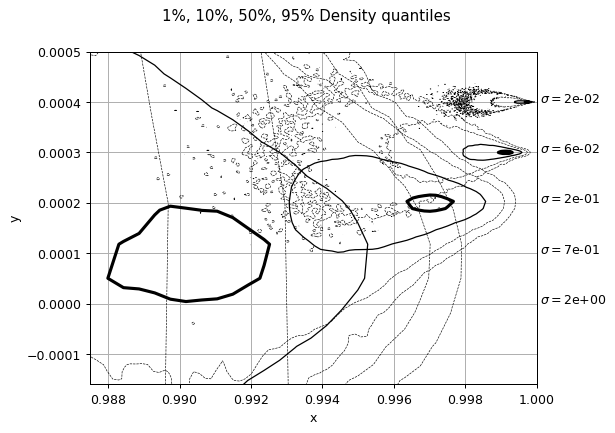

In [24]:
res_ = results_null[-10::2]
cmap = cm.get_cmap('inferno', len(res_))
for i, r_ in tqdm(enumerate(res_), total=len(res_)):
    density_analysis(r_, use_rotated=True, nbins=500)
    plot_density(r_, c='k', gaussian_filter_sigma=1, offset_y=i/10000)
    plt.plot([],[], color=cmap(i), label=f"$\sigma=${r_['sigma']:.0f}")
    plt.text(1.0001, 0 + i / 10000, f"$\sigma=${r_['sigma']:.0e}")

    
plt.xlim((0.9875,1)), plt.ylim((-0.00016, 0.0005))
#plt.plot([0],[0],'+k', markersize=10)
#plt.plot([1],[0],'+k', markersize=10)
plt.grid()
plt.suptitle("1%, 10%, 50%, 95% Density quantiles")
plt.savefig("img/5/6_dens_null_lownoise.png")
plt.show()

### Localization

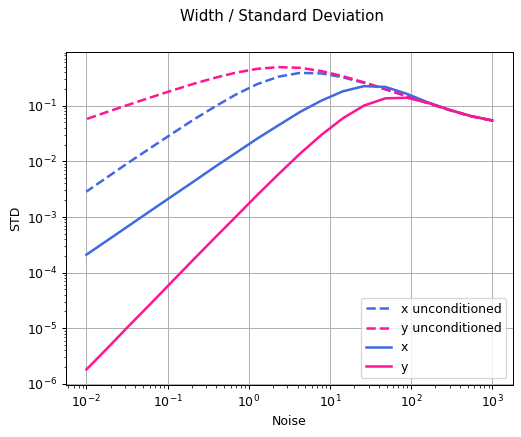

In [25]:
plot_std(results_unconditioned,
         x_label='x unconditioned',
         y_label='y unconditioned',
         rot_style='--'
        )

plot_std(results_null,
         x_label='x',
         y_label='y',
         rot_style='-'
        )
plt.legend(), plt.grid()
plt.savefig("img/5/7_std_null.png")
plt.show()

### Efficiency

100%|███████████████████████████████████████████| 20/20 [01:53<00:00,  5.67s/it]


Elapsed time: 10 minutes, 32 seconds


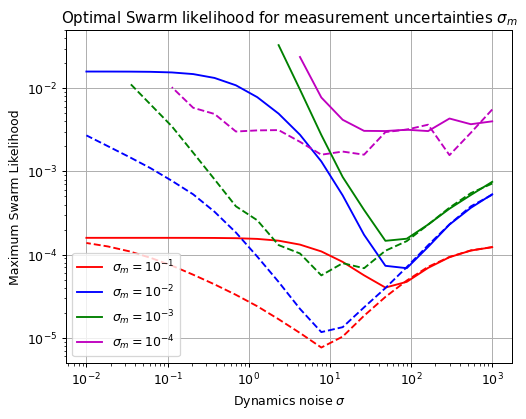

In [26]:
lkhd_uc_1 = plot_optimal_likelihood(results_unconditioned, 1e-1, use_tqdm=True, style='--', color='r')
lkhd_nl_1 = plot_optimal_likelihood(results_null, 1e-1, use_tqdm=True, style='-', color='r', label='$\sigma_m=10^{-1}$', reference_results=results_unconditioned)

lkhd_uc_2 = plot_optimal_likelihood(results_unconditioned, 1e-2, use_tqdm=True, style='--', color='b')
lkhd_nl_2 = plot_optimal_likelihood(results_null, 1e-2, use_tqdm=True, style='-', color='b', label='$\sigma_m=10^{-2}$', reference_results=results_unconditioned)

lkhd_uc_3 = plot_optimal_likelihood(results_unconditioned, 1e-3, use_tqdm=True, style='--', color='g')
lkhd_nl_3 = plot_optimal_likelihood(results_null, 1e-3, use_tqdm=True, style='-', color='g', label='$\sigma_m=10^{-3}$', reference_results=results_unconditioned)

lkhd_uc_4 = plot_optimal_likelihood(results_unconditioned, 1e-4, use_tqdm=True, style='--', color='m')
lkhd_nl_4 = plot_optimal_likelihood(results_null, 1e-4, use_tqdm=True, style='-', color='m', label='$\sigma_m=10^{-4}$', reference_results=results_unconditioned)
toc()
plt.title('Optimal Swarm likelihood for measurement uncertainties $\sigma_m$')
plt.xlabel('Dynamics noise $\sigma$')
plt.ylabel('Maximum Swarm Likelihood')
plt.legend()
plt.grid()
plt.savefig("img/5/8_lklhd_null_vs_uncond.png")
plt.show()

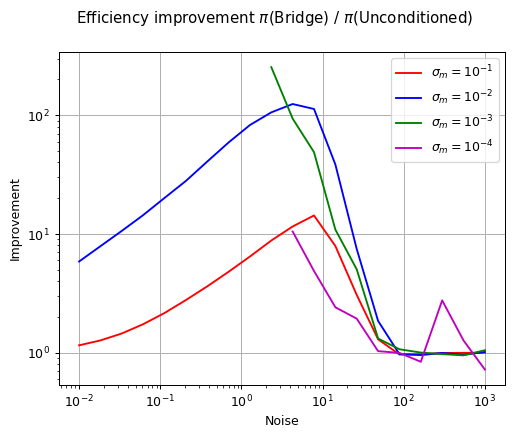

In [27]:
idx_ = (lkhd_nl_1['likelihood'] > 1e-10) * (lkhd_uc_1['likelihood'] > 1e-10)
plt.loglog(lkhd_uc_1['sigma'][idx_], lkhd_nl_1['likelihood'][idx_]/lkhd_uc_1['likelihood'][idx_], 'r', label='$\sigma_m=10^{-1}$')
idx_ = (lkhd_nl_2['likelihood'] > 1e-10) * (lkhd_uc_2['likelihood'] > 1e-10)
plt.loglog(lkhd_uc_2['sigma'][idx_], lkhd_nl_2['likelihood'][idx_]/lkhd_uc_2['likelihood'][idx_], 'b', label='$\sigma_m=10^{-2}$')
idx_ = (lkhd_nl_3['likelihood'] > 1e-10) * (lkhd_uc_3['likelihood'] > 1e-10)
plt.loglog(lkhd_uc_3['sigma'][idx_], lkhd_nl_3['likelihood'][idx_]/lkhd_uc_3['likelihood'][idx_], 'g', label='$\sigma_m=10^{-3}$')
idx_ = (lkhd_nl_4['likelihood'] > 1e-10) * (lkhd_uc_4['likelihood'] > 1e-10)
plt.loglog(lkhd_uc_4['sigma'][idx_], lkhd_nl_4['likelihood'][idx_]/lkhd_uc_4['likelihood'][idx_], '-m', label='$\sigma_m=10^{-4}$')

plt.legend()
plt.grid()
plt.xlabel('Noise')
plt.ylabel('Improvement')
plt.suptitle('Efficiency improvement $\pi$(Bridge) / $\pi$(Unconditioned)')
plt.savefig("img/5/9_lklhd_improv_null_unsynced.png")
plt.show()

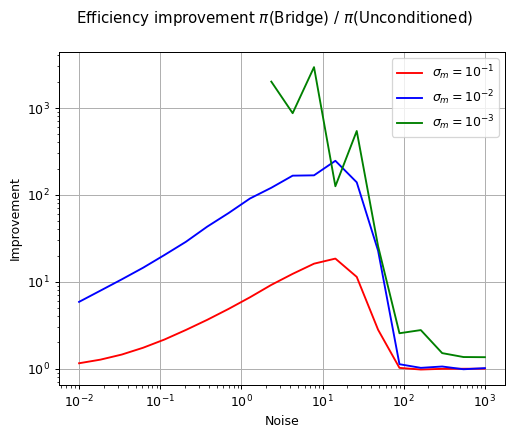

In [28]:
idx_ = (lkhd_nl_1['likelihood'] > 1e-10) * ((lkhd_nl_1['likelihood_reference'] > 1e-10))
plt.loglog(lkhd_uc_1['sigma'][idx_], gaussian_filter(lkhd_nl_1['likelihood'][idx_]/lkhd_nl_1['likelihood_reference'][idx_], 0), 'r', label='$\sigma_m=10^{-1}$')

idx_ = (lkhd_nl_2['likelihood'] > 1e-10) * ((lkhd_nl_2['likelihood_reference'] > 1e-10))
plt.loglog(lkhd_uc_2['sigma'][idx_], gaussian_filter(lkhd_nl_2['likelihood'][idx_]/lkhd_nl_2['likelihood_reference'][idx_], 0), 'b', label='$\sigma_m=10^{-2}$')

idx_ = (lkhd_nl_3['likelihood'] > 1e-10) * ((lkhd_nl_3['likelihood_reference'] > 1e-10))
plt.loglog(lkhd_uc_3['sigma'][idx_], gaussian_filter(lkhd_nl_3['likelihood'][idx_]/lkhd_nl_3['likelihood_reference'][idx_], 0), 'g', label='$\sigma_m=10^{-3}$')

#idx_ = (lkhd_nl_4['likelihood'] > 1e-10) * ((lkhd_nl_4['likelihood_reference'] > 1e-10))
#plt.loglog(lkhd_uc_4['sigma'][idx_], lkhd_nl_4['likelihood'][idx_]/lkhd_nl_4['likelihood_reference'][idx_], '-m', label='$\sigma_m=10^{-3}$')

plt.legend()
plt.grid()
plt.xlabel('Noise')
plt.ylabel('Improvement')
plt.suptitle('Efficiency improvement $\pi$(Bridge) / $\pi$(Unconditioned)')
plt.savefig("img/5/10_lklhd_improv_null_synced.png")
plt.show()

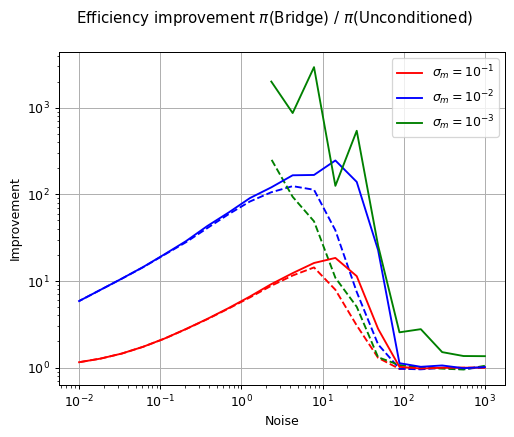

In [29]:
idx_ = (lkhd_nl_1['likelihood'] > 1e-10) * (lkhd_uc_1['likelihood'] > 1e-10)
plt.loglog(lkhd_uc_1['sigma'][idx_], lkhd_nl_1['likelihood'][idx_]/lkhd_uc_1['likelihood'][idx_], '--r')
idx_ = (lkhd_nl_2['likelihood'] > 1e-10) * (lkhd_uc_2['likelihood'] > 1e-10)
plt.loglog(lkhd_uc_2['sigma'][idx_], lkhd_nl_2['likelihood'][idx_]/lkhd_uc_2['likelihood'][idx_], '--b')
idx_ = (lkhd_nl_3['likelihood'] > 1e-10) * (lkhd_uc_3['likelihood'] > 1e-10)
plt.loglog(lkhd_uc_3['sigma'][idx_], lkhd_nl_3['likelihood'][idx_]/lkhd_uc_3['likelihood'][idx_], '--g')


idx_ = (lkhd_nl_1['likelihood'] > 1e-10) * ((lkhd_nl_1['likelihood_reference'] > 1e-10))
plt.loglog(lkhd_uc_1['sigma'][idx_], lkhd_nl_1['likelihood'][idx_]/lkhd_nl_1['likelihood_reference'][idx_], 'r', label='$\sigma_m=10^{-1}$')

idx_ = (lkhd_nl_2['likelihood'] > 1e-10) * ((lkhd_nl_2['likelihood_reference'] > 1e-10))
plt.loglog(lkhd_uc_2['sigma'][idx_], lkhd_nl_2['likelihood'][idx_]/lkhd_nl_2['likelihood_reference'][idx_], 'b', label='$\sigma_m=10^{-2}$')

idx_ = (lkhd_nl_3['likelihood'] > 1e-10) * ((lkhd_nl_3['likelihood_reference'] > 1e-10))
plt.loglog(lkhd_uc_3['sigma'][idx_], lkhd_nl_3['likelihood'][idx_]/lkhd_nl_3['likelihood_reference'][idx_], 'g', label='$\sigma_m=10^{-3}$')


plt.legend()
plt.grid()
plt.xlabel('Noise')
plt.ylabel('Improvement')
plt.suptitle('Efficiency improvement $\pi$(Bridge) / $\pi$(Unconditioned)')
plt.savefig("img/5/11_lklhd_improv_null_synccompare.png")
plt.show()

## Shift conditioning

### Data generation

In [30]:
params = dict(BridgeGen=bridge_gen,
              sigma = 1,
              dt = _THE_DT_,
              target_shift_PHI=0,
              target_slope_PHI=0*np.pi,
              output_hires=True,
              omit_bridges=False,
              use_tqdm = False,
             )

params['RNG'] = crng()

N = _THE_NUMBER_OF_PARTICLES_
results_shift_0 = []
sigma_ = 1

results_shifts = []

for sigma_ in tqdm(_THE_SIGMAS_):
    bundle_ = []
    for shift_ in _THE_SHIFTS_:
        res = run(N=N, sigma=sigma_, shift=shift_, slope=0, params=params, use_tqdm=False)
        analyze(res)
        res['sigma'] = sigma_
        res['shift'] = shift_
        bundle_.append(res)
    results_shifts.append(bundle_)

toc()

100%|███████████████████████████████████████████| 20/20 [02:49<00:00,  8.48s/it]

Elapsed time: 13 minutes, 23 seconds


In [31]:
params = dict(BridgeGen=bridge_gen,
              sigma = 1,
              dt = _THE_DT_,
              target_shift_PHI=0,
              target_slope_PHI=0*np.pi,
              output_hires=True,
              omit_bridges=False,
              use_tqdm = False,
             )

params['RNG'] = crng()

N = _THE_NUMBER_OF_PARTICLES_
results_shift_0 = []
sigma_ = 1

for shift_ in tqdm(np.linspace(0,1,10)):
    res = run(N=N, sigma=sigma_, shift=shift_, slope=0, params=params, use_tqdm=False)
    analyze(res)
    res['sigma'] = sigma_
    res['shift'] = shift_
    results_shift_0.append(res)
    
results_shift_1 = []
sigma_ = 0.1
for shift_ in tqdm(np.linspace(0,1,10)):
    res = run(N=N, sigma=sigma_, shift=shift_, slope=0, params=params, use_tqdm=False)
    analyze(res)
    res['sigma'] = sigma_
    res['shift'] = shift_
    results_shift_1.append(res)
    
results_shift_2 = []
sigma_ = 0.01
for shift_ in tqdm(np.linspace(0,1,10)):
    res = run(N=N, sigma=sigma_, shift=shift_, slope=0, params=params, use_tqdm=False)
    analyze(res)
    res['sigma'] = sigma_
    res['shift'] = shift_
    results_shift_2.append(res)

toc()

100%|███████████████████████████████████████████| 10/10 [00:07<00:00,  1.26it/s]

Elapsed time: 13 minutes, 48 seconds


### Density Plots

In [32]:
for num, res_ in enumerate(tqdm(results_shifts)):
    plt.figure()    
    cmap = cm.get_cmap('rainbow', len(_THE_SHIFTS_))
    for i, r_ in enumerate(res_):


        X0 = np.zeros((1000, 3))
        params = dict(RNG=crng(), BridgeGen=bridge_gen,
                      sigma = r_['sigma'],
                      dt = dt,
                      target_shift_PHI=r_['shift'],
                      target_slope_PHI=0*np.pi,
                      output_hires=True,
                      omit_bridges=False,
                      use_tqdm = False,
                     )
        
        sim_res = abp_sde(X0, params)
        x = sim_res['per_particle_streams']['hires'][:,0,:].T
        y = sim_res['per_particle_streams']['hires'][:,1,:].T

        #x = np.mean(x, axis=1)
        #y = np.mean(y, axis=1)

        plt.plot(x,y, c=cmap(i), linewidth=0.1, alpha=0.1)

        density_analysis(r_, use_rotated=False, nbins=500)
        dark_color = [mult * channel for channel, mult in zip(cmap(i), [0.75, 0.75, 0.75, 1])]
        plot_density(r_, c=dark_color, gaussian_filter_sigma=5)
        
        #angle_ = np.arctan2(r_['y_loc'], r_['x_loc'])
        #dx_ = np.cos(angle_)
        #dy_ = np.sin(angle_)
        #off_ = 0.06
        #x_ = r_['x_loc'] + off_ * dx_
        #y_ = r_['y_loc'] + off_ * dy_
        #plt.text(x_, y_, f"{r_['shift']:.1f}")
        #plt.plot([],[], color=cmap(i))
    
        
    #plt.xlim((0.9875,1)), plt.ylim((-0.00005, 0.0004))
    plt.xlim((-.05, 1.1))
    plt.ylim((-.05, 0.9))
    plt.plot([0],[0],'+r', markersize=10)
    #plt.plot([1],[0],'+k', markersize=10)
    plt.grid()
    norm = mpl.colors.BoundaryNorm(_THE_SHIFTS_, cmap.N)
    cb = plt.colorbar(cm.ScalarMappable(norm, cmap),shrink=1)
    cb.set_label("Shift condition")
    #plt.legend(loc='lower left')
    #plt.gca().axis('equal')
    plt.suptitle(f"1%, 10%, 50%, 95% Density quantiles, $\sigma={r_['sigma']:.1g}$")
    plt.savefig(f"img/5/12_dens_shift_sig{num}.png")
    plt.close()

  0%|                                                    | 0/20 [00:00<?, ?it/s]/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_52849/1495727106.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('rainbow', len(_THE_SHIFTS_))
/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_52849/1495727106.py:48: MatplotlibDeprecationWarning: Unable to determine Axes to steal space for Colorbar. Using gca(), but will raise in the future. Either provide the *cax* argument to use as the Axes for the Colorbar, provide the *ax* argument to steal space from it, or add *mappable* to an Axes.
  cb = plt.colorbar(cm.ScalarMappable(norm, cmap),shrink=1)
100%|███████████████████████████████████████████| 20/20 [01:02<00:00,  3.10s/it]


In [33]:
for num, res_ in enumerate(tqdm(results_shifts)):
    plt.figure()
    cmap = cm.get_cmap('inferno', len(res_))
    for i, r_ in enumerate(res_):
        density_analysis(r_, use_rotated=True, nbins=500)
        plot_density(r_, c='k', gaussian_filter_sigma=5)
        
        angle_ = np.arctan2(r_['y_loc_rot'], r_['x_loc_rot'])
        dx_ = np.cos(angle_)
        dy_ = np.sin(angle_)
        off_ = 0.00
        x_ = r_['x_loc_rot']
        y_ = r_['y_loc_rot']
        
        plt.annotate(f"{r_['shift']:.1f}", (x_, y_ + 0.001), (0.88 + 0.0105 * (len(res_) - i), 0.008 - i * 0.0007),
                     arrowprops=dict(arrowstyle="->",
                        shrinkA=0, shrinkB=0,
                        connectionstyle="angle,angleA=0,angleB=90,rad=20")
                    
                    )
        plt.plot([],[], color=cmap(i))
    
        
    #plt.xlim((0.9875,1)), plt.ylim((-0.00005, 0.0004))
    plt.xlim((0.86, 1.01))
    plt.ylim((-.004, 0.009))
    plt.plot([0],[0],'+r', markersize=10)
    #plt.plot([1],[0],'+k', markersize=10)
    plt.grid()
    #plt.legend(loc='lower left')
    #plt.gca().axis('equal')
    plt.suptitle(f"1%, 10%, 50%, 95% Density quantiles, $\sigma={r_['sigma']:.1g}$")
    plt.savefig(f"img/5/16_densrot_shift_sig{num}.png")
    plt.close()

  0%|                                                    | 0/20 [00:00<?, ?it/s]/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_52849/2255569894.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('inferno', len(res_))
100%|███████████████████████████████████████████| 20/20 [00:14<00:00,  1.34it/s]


### Localization

/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_52849/1818101551.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmapy = (cm.get_cmap('PuRd_r', len(bundles_)))
/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_52849/1818101551.py:4: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmapx = cm.get_cmap('BuPu_r', len(bundles_))
100%|████████████████████████████████████████████| 9/9 [00:00<00:00, 690.28it/s]
/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_52849/1818101551.py:35: MatplotlibDeprecationWarning: Unable to determine Axes to steal space for Colorbar. Using gca(), but will raise in the future. Either provide 

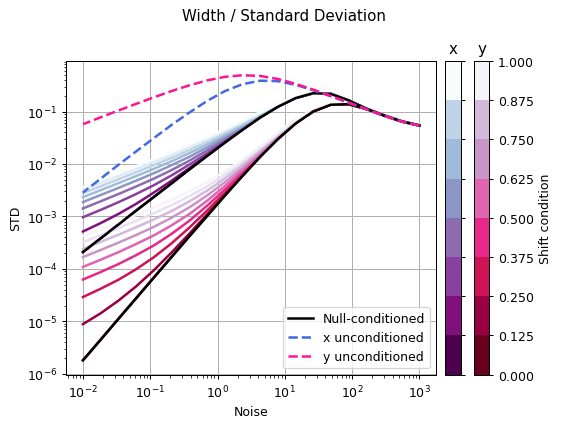

In [34]:

bundles_ = list(zip(*results_shifts))

cmapy = (cm.get_cmap('PuRd_r', len(bundles_)))
cmapx = cm.get_cmap('BuPu_r', len(bundles_))

for num, res_ in enumerate(tqdm(bundles_)):
    
    style_ = '-'
    plot_std(res_,
             rot_style=style_,
             x_label=None,
             y_label=None,
             x_color=cmapx(num),
             y_color=cmapy(num),
            )

plot_std(results_null,
         x_label='Null-conditioned',
         y_label=None,
         rot_style='-',
         x_color= 'k',
         y_color='k'
        )

plot_std(results_unconditioned,
         x_label='x unconditioned',
         y_label='y unconditioned',
         rot_style='--'
        )

plt.legend(), plt.grid()

norm = mpl.colors.BoundaryNorm(_THE_SHIFTS_, cmapx.N)

cbb = plt.colorbar(cm.ScalarMappable(norm, cmapy),shrink=1, pad=-0.08)
cba = plt.colorbar(cm.ScalarMappable(norm, cmapx),shrink=1, pad = 0.02)
cbb.ax.set_title('y')
cbb.set_label('Shift condition')
cba.ax.set_title('x')
cba.set_ticklabels([])
plt.tight_layout()
plt.savefig("img/5/18_std_shift.png")
plt.show()

### Efficiency

100%|█████████████████████████████████████████████| 3/3 [00:08<00:00,  2.81s/it]


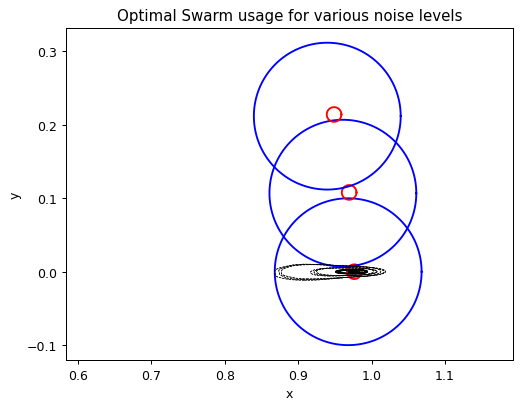

Elapsed time: 15 minutes, 14 seconds


In [35]:
''' for debug '''
for res_ in tqdm([results_shift_0[i] for i in [0, 1, 2]]):
    density_analysis(res_)
    maximize_data_likelihood(res_, sigma=1e-1, restrict_to_x=False)
    plot_density(res_, gaussian_filter_sigma=30, plot_optimization_result=True, optimization_style='-b')
    maximize_data_likelihood(res_, sigma=1e-2, restrict_to_x=False)
    plot_density(res_, gaussian_filter_sigma=30, plot_optimization_result=True, optimization_style='-r')
    #plt.xlim((-0.5,1.5))
    #plt.ylim((-1.5,1.5))
plt.title('Optimal Swarm usage for various noise levels')
plt.gca().axis('equal')
#plt.savefig("img/5/4_dens_opt_uncond.png")
plt.show()
toc()

100%|███████████████████████████████████████████| 20/20 [00:13<00:00,  1.45it/s]
/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_52849/320840344.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap1 = cm.get_cmap('RdPu_r', len(_THE_SHIFTS_))
100%|███████████████████████████████████████████| 20/20 [00:22<00:00,  1.13s/it]
/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_52849/320840344.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap2 = cm.get_cmap('PuBu_r', len(_THE_SHIFTS_))
100%|███████████████████████████████████████████| 20/20 [01:15<00:00,  3.75s/it]
/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_

Elapsed time: 26 minutes, 18 seconds


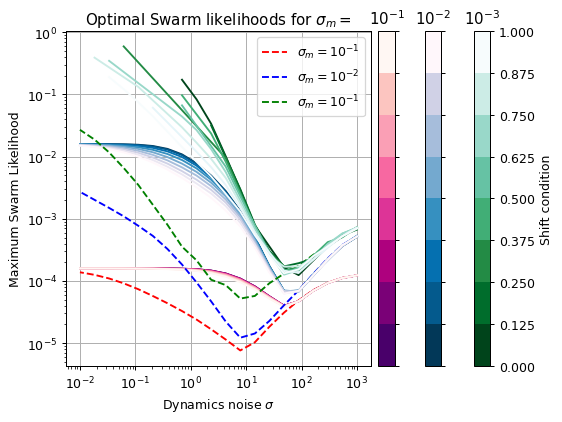

In [36]:
lkhd_uc_1 = plot_optimal_likelihood(results_unconditioned, 1e-1, use_tqdm=True, style='--', color='r', label='$\sigma_m=10^{-1}$')
cmap1 = cm.get_cmap('RdPu_r', len(_THE_SHIFTS_))
for num, bundle_ in tqdm(enumerate(bundles_), total=len(_THE_SHIFTS_)):
    plot_optimal_likelihood(bundle_, 1e-1, use_tqdm=False, style='-',label='_$\sigma_m=10^{-1}$', color=cmap1(num))

lkhd_uc_2 = plot_optimal_likelihood(results_unconditioned, 1e-2, use_tqdm=True, style='--', color='b', label='$\sigma_m=10^{-2}$')
cmap2 = cm.get_cmap('PuBu_r', len(_THE_SHIFTS_))
for num, bundle_ in tqdm(enumerate(bundles_), total=len(_THE_SHIFTS_)):
    plot_optimal_likelihood(bundle_, 1e-2, use_tqdm=False, style='-',label='_$\sigma_m=10^{-1}$', color=cmap2(num))

lkhd_uc_3 = plot_optimal_likelihood(results_unconditioned, 1e-3, use_tqdm=True, style='--', color='g' , label='$\sigma_m=10^{-1}$')
cmap3 = cm.get_cmap('BuGn_r', len(_THE_SHIFTS_))
for num, bundle_ in tqdm(enumerate(bundles_), total=len(_THE_SHIFTS_)):
    plot_optimal_likelihood(bundle_, 1e-3, use_tqdm=False, style='-',label='_$\sigma_m=10^{-1}$', color=cmap3(num))

toc()
plt.title('Optimal Swarm likelihoods for $\sigma_m=$')
plt.xlabel('Dynamics noise $\sigma$')
plt.ylabel('Maximum Swarm Likelihood')
plt.legend()
plt.grid()
norm = mpl.colors.BoundaryNorm(_THE_SHIFTS_, cmapx.N)

cb3 = plt.colorbar(cm.ScalarMappable(norm, cmap3),shrink=1, pad = -0.03)
cb2 = plt.colorbar(cm.ScalarMappable(norm, cmap2),shrink=1, pad = -0.02)
cb1 = plt.colorbar(cm.ScalarMappable(norm, cmap1),shrink=1, pad= 0.02)


cb1.set_ticklabels([])
cb2.set_ticklabels([])
cb3.set_label("Shift condition")

cb1.ax.set_title('$10^{-1}$')
cb2.ax.set_title('$10^{-2}$')
cb3.ax.set_title('$10^{-3}$')

plt.tight_layout()

plt.savefig("img/5/19_lklhd_shift_vs_uncond.png")
plt.show()

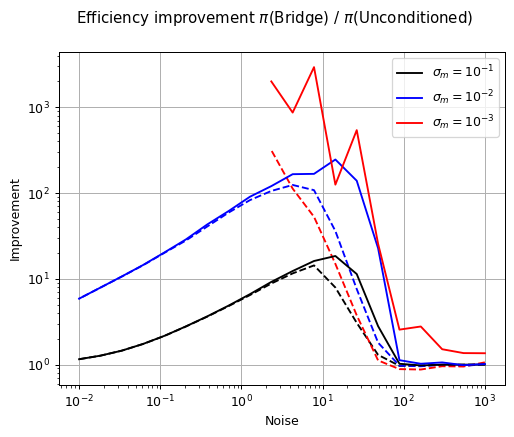

In [37]:
idx_ = (lkhd_nl_1['likelihood'] > 1e-10) * (lkhd_uc_1['likelihood'] > 1e-10)
plt.loglog(lkhd_uc_1['sigma'][idx_], lkhd_nl_1['likelihood'][idx_]/lkhd_uc_1['likelihood'][idx_], '--k')
idx_ = (lkhd_nl_2['likelihood'] > 1e-10) * (lkhd_uc_2['likelihood'] > 1e-10)
plt.loglog(lkhd_uc_2['sigma'][idx_], lkhd_nl_2['likelihood'][idx_]/lkhd_uc_2['likelihood'][idx_], '--b')
idx_ = (lkhd_nl_3['likelihood'] > 1e-10) * (lkhd_uc_3['likelihood'] > 1e-10)
plt.loglog(lkhd_uc_3['sigma'][idx_], lkhd_nl_3['likelihood'][idx_]/lkhd_uc_3['likelihood'][idx_], '--r')


idx_ = (lkhd_nl_1['likelihood'] > 1e-10) * ((lkhd_nl_1['likelihood_reference'] > 1e-10))
plt.loglog(lkhd_uc_1['sigma'][idx_], lkhd_nl_1['likelihood'][idx_]/lkhd_nl_1['likelihood_reference'][idx_], 'k', label='$\sigma_m=10^{-1}$')

idx_ = (lkhd_nl_2['likelihood'] > 1e-10) * ((lkhd_nl_2['likelihood_reference'] > 1e-10))
plt.loglog(lkhd_uc_2['sigma'][idx_], lkhd_nl_2['likelihood'][idx_]/lkhd_nl_2['likelihood_reference'][idx_], 'b', label='$\sigma_m=10^{-2}$')

idx_ = (lkhd_nl_3['likelihood'] > 1e-10) * ((lkhd_nl_3['likelihood_reference'] > 1e-10))
plt.loglog(lkhd_uc_3['sigma'][idx_], lkhd_nl_3['likelihood'][idx_]/lkhd_nl_3['likelihood_reference'][idx_], 'r', label='$\sigma_m=10^{-3}$')


plt.legend()
plt.grid()
plt.xlabel('Noise')
plt.ylabel('Improvement')
plt.suptitle('Efficiency improvement $\pi$(Bridge) / $\pi$(Unconditioned)')
#plt.savefig("img/5/20_lklhd_improv_shift_synccompare.png")
plt.show()

## Slope Conditioning

### Data Generation

In [38]:
params = dict(BridgeGen=bridge_gen,
              sigma = 1,
              dt = _THE_DT_,
              target_shift_PHI=0,
              target_slope_PHI=0*np.pi,
              output_hires=True,
              omit_bridges=False,
              use_tqdm = False,
             )

params['RNG'] = crng()

N = _THE_NUMBER_OF_PARTICLES_

results_slopes = []

for sigma_ in tqdm(_THE_SIGMAS_):
    bundle_ = []
    for slope_ in _THE_SLOPES_:
        res = run(N=N, sigma=sigma_, shift=0, slope=slope_, params=params, use_tqdm=False)
        analyze(res)
        res['sigma'] = sigma_
        res['shift'] = 0
        res['slope'] = slope_
        bundle_.append(res)
    results_slopes.append(bundle_)

toc()

100%|███████████████████████████████████████████| 20/20 [02:40<00:00,  8.01s/it]

Elapsed time: 28 minutes, 59 seconds


### Density Plots

In [39]:
for num, res_ in enumerate(tqdm((results_slopes))):
    plt.figure()    
    cmap = cm.get_cmap('rainbow', len(_THE_SLOPES_))
    for i, r_ in enumerate(res_):

        X0 = np.zeros((1000, 3))
        params = dict(RNG=crng(), BridgeGen=bridge_gen,
                      sigma = r_['sigma'],
                      dt = _THE_DT_,
                      target_shift_PHI=r_['shift'],
                      target_slope_PHI=r_['slope'],
                      output_hires=True,
                      omit_bridges=False,
                      use_tqdm = False,
                     )
        
        sim_res = abp_sde(X0, params)
        x = sim_res['per_particle_streams']['hires'][:,0,:].T
        y = sim_res['per_particle_streams']['hires'][:,1,:].T

        #x = np.mean(x, axis=1)
        #y = np.mean(y, axis=1)

        plt.plot(x,y, c=cmap(i), linewidth=0.1, alpha=0.1)

        density_analysis(r_, use_rotated=False, nbins=500)
        dark_color = [mult * channel for channel, mult in zip(cmap(i), [0.75, 0.75, 0.75, 1])]
        plot_density(r_, c=dark_color, gaussian_filter_sigma=5)
        
        #angle_ = np.arctan2(r_['y_loc'], r_['x_loc'])
        #dx_ = np.cos(angle_)
        #dy_ = np.sin(angle_)
        #off_ = 0.06
        #x_ = r_['x_loc'] + off_ * dx_
        #y_ = r_['y_loc'] + off_ * dy_
        #plt.text(x_, y_, f"{r_['shift']:.1f}")
        #plt.plot([],[], color=cmap(i))
    
        
    #plt.xlim((0.9875,1)), plt.ylim((-0.00005, 0.0004))
    plt.xlim((-.25, 1.1))
    plt.ylim((-.5, 0.1))
    plt.plot([0],[0],'+r', markersize=10)
    #plt.plot([1],[0],'+k', markersize=10)
    plt.grid()
    norm = mpl.colors.BoundaryNorm(_THE_SLOPES_, cmap.N)
    cb = plt.colorbar(cm.ScalarMappable(norm, cmap),shrink=1)
    cb.set_label("Slope condition")
    #plt.legend(loc='lower left')
    #plt.gca().axis('equal')
    plt.suptitle(f"1%, 10%, 50%, 95% Density quantiles, $\sigma={r_['sigma']:.1g}$")
    plt.savefig(f"img/5/20_dens_slope_sig{num}.png")
    plt.close()

  0%|                                                    | 0/20 [00:00<?, ?it/s]/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_52849/4154845162.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('rainbow', len(_THE_SLOPES_))
/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_52849/4154845162.py:47: MatplotlibDeprecationWarning: Unable to determine Axes to steal space for Colorbar. Using gca(), but will raise in the future. Either provide the *cax* argument to use as the Axes for the Colorbar, provide the *ax* argument to steal space from it, or add *mappable* to an Axes.
  cb = plt.colorbar(cm.ScalarMappable(norm, cmap),shrink=1)
100%|███████████████████████████████████████████| 20/20 [01:14<00:00,  3.73s/it]


In [40]:
for num, res_ in enumerate(tqdm(results_slopes)):
    plt.figure()    
    cmap = cm.get_cmap('rainbow', len(_THE_SLOPES_))
    for i, r_ in enumerate(res_):

        density_analysis(r_, use_rotated=False, nbins=500)
        dark_color = [mult * channel for channel, mult in zip(cmap(i), [0.75, 0.75, 0.75, 1])]
        plot_density(r_, c=cmap(i), gaussian_filter_sigma=5)
        
        #angle_ = np.arctan2(r_['y_loc'], r_['x_loc'])
        #dx_ = np.cos(angle_)
        #dy_ = np.sin(angle_)
        #off_ = 0.06
        #x_ = r_['x_loc'] + off_ * dx_
        #y_ = r_['y_loc'] + off_ * dy_
        #plt.text(x_, y_, f"{r_['shift']:.1f}")
        #plt.plot([],[], color=cmap(i))
    
        
    #plt.xlim((0.9875,1)), plt.ylim((-0.00005, 0.0004))
    plt.xlim((0.52, 1.01))
    plt.ylim((-.16, 0.012))
    plt.plot([0],[0],'+r', markersize=10)
    #plt.plot([1],[0],'+k', markersize=10)
    plt.grid()
    norm = mpl.colors.BoundaryNorm(_THE_SLOPES_, cmap.N)
    cb = plt.colorbar(cm.ScalarMappable(norm, cmap),shrink=1)
    cb.set_label("Slope condition")
    #plt.legend(loc='lower left')
    #plt.gca().axis('equal')
    plt.axhline(0, c='k')
    plt.plot([1],[0], 'ko')
    plt.suptitle(f"1%, 10%, 50%, 95% Density quantiles, $\sigma={r_['sigma']:.1g}$")
    plt.savefig(f"img/5/20_dens_slope_sig{num}_close.png")
    plt.close()

  0%|                                                    | 0/20 [00:00<?, ?it/s]/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_52849/1541552132.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('rainbow', len(_THE_SLOPES_))
/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_52849/1541552132.py:27: MatplotlibDeprecationWarning: Unable to determine Axes to steal space for Colorbar. Using gca(), but will raise in the future. Either provide the *cax* argument to use as the Axes for the Colorbar, provide the *ax* argument to steal space from it, or add *mappable* to an Axes.
  cb = plt.colorbar(cm.ScalarMappable(norm, cmap),shrink=1)
100%|███████████████████████████████████████████| 20/20 [00:15<00:00,  1.33it/s]


## Bridge Likelihoods

In [41]:
''' Boundary for the bridges to have a 50% chance of outliers in 1.000.000 samples taken '''
binom.cdf(0.5, n=1e6, p=6.93e-7)

0.5000734756158045

In [42]:
min_me = lambda p: binom.cdf(0.5, n=1e6, p=p) - 0.5
log_sol_bound = np.log10(fsolve(min_me, 6.93e-7)[0])
log_sol_bound

-6.159174689469851

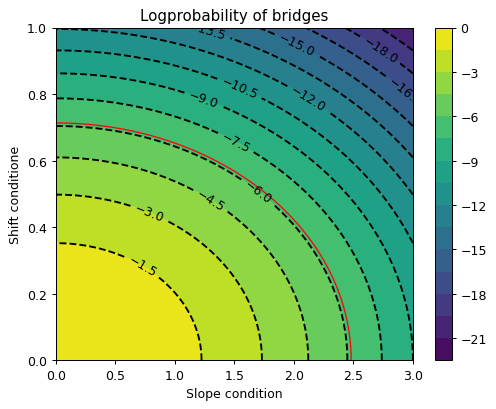

In [43]:
N = 1
dt = 1e-1
X0 = np.zeros((N, 3))

n = 100
shift_max = 1
slope_max = 3
shifts_ = np.linspace(0,shift_max,n)
slopes_ = np.linspace(0,slope_max,n)
results_ = []
for shift_, slope_ in list(product(shifts_, slopes_)):
    params = dict(RNG=crng(), BridgeGen=bridge_gen,
              sigma = 1e-0,
              dt = dt,
              target_shift_PHI=shift_,
              target_slope_PHI=slope_,
              output_hires=True,
              omit_bridges=False,
              use_tqdm = False,
             )
    sim_res = abp_sde(X0, params)
    results_.append(sim_res['logl'])

nbins = 20
logl = np.array(results_).reshape((-1,n))
levels = np.arange(-21, 1)
plt.contourf(logl, levels=nbins, extent=(0,slope_max,0, shift_max))
plt.colorbar()
plt.contour(logl, [log_sol_bound], colors='r', linestyles='-', linewidths=1, extent=(0,slope_max,0,shift_max))
C = plt.contour(logl, levels=nbins, colors='k', extent=(0,slope_max,0,shift_max))
plt.gca().clabel(C, C.levels)
plt.title("Logprobability of bridges")
plt.xlabel("Slope condition")
plt.ylabel("Shift conditione")
plt.savefig("img/5/logprobs_bridges.png")

/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_52849/4177233250.py:12: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = (cm.get_cmap('plasma', n_sigmas_))
100%|███████████████████████████████████████████| 21/21 [05:42<00:00, 16.32s/it]
/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_52849/4177233250.py:36: MatplotlibDeprecationWarning: Unable to determine Axes to steal space for Colorbar. Using gca(), but will raise in the future. Either provide the *cax* argument to use as the Axes for the Colorbar, provide the *ax* argument to steal space from it, or add *mappable* to an Axes.
  cb1 = plt.colorbar(cm.ScalarMappable(norm, cmap),shrink=1)


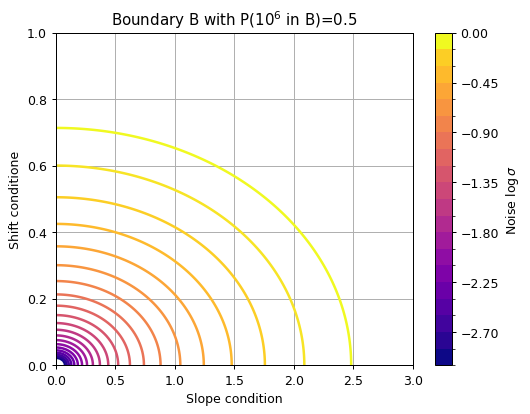

In [44]:
N = 1
dt = 1e-1
X0 = np.zeros((N, 3))

n = 150
shift_max = 1
slope_max = 3
shifts_ = np.linspace(0,shift_max,n)
slopes_ = np.linspace(0,slope_max,n)

n_sigmas_ = 21
cmap = (cm.get_cmap('plasma', n_sigmas_))
sigmas_ = np.logspace(-3,0, n_sigmas_)
for num, sigma_ in tqdm(enumerate(sigmas_), total=n_sigmas_):
    results_ = []
    for shift_, slope_ in list(product(shifts_, slopes_)):
        params = dict(RNG=crng(), BridgeGen=bridge_gen,
                  sigma = sigma_,
                  dt = dt,
                  target_shift_PHI=shift_,
                  target_slope_PHI=slope_,
                  output_hires=True,
                  omit_bridges=False,
                  use_tqdm = False,
                 )
        sim_res = abp_sde(X0, params)
        results_.append(sim_res['logl'])
    
    nbins = 20
    logl = np.array(results_).reshape((-1,n))
    levels = np.arange(-21, 1)
    plt.contour(logl, [log_sol_bound], linestyles='-', linewidths=2, colors=[cmap(num)], extent=(0,slope_max,0,shift_max))
    plt.gca().clabel(C, C.levels)

norm = mpl.colors.BoundaryNorm(np.log10(sigmas_), cmap.N)
cb1 = plt.colorbar(cm.ScalarMappable(norm, cmap),shrink=1)
cb1.set_label("Noise $\log\sigma$")
plt.title("Boundary B with P($10^6$ in B)=0.5")
plt.xlabel("Slope condition")
plt.ylabel("Shift conditione")
plt.grid()
plt.savefig("img/5/bridge_boundaries.png")